# Single-Stock Risk Report

**HW2 Part 2: parameterized report template** · Author: Farshid Gilak

This notebook produces a standardized risk report for **one ticker over one date window** from the cleaned table `ohlc_hw_cleaned`, which Part 1 (`01_data_cleaning.ipynb`) creates. It is written to run unattended under **papermill**: the next cell carries the `parameters` tag, so `03_run_all_stocks.py` can inject a different ticker and window for every stock.

**How to read this report:**

1. **Coverage.** Compare the *requested* window with the *actual* first and last observation. Supplied histories end on different dates, and nothing is extrapolated past a ticker's last observation.
2. **Data provenance.** Lists any values in the window that Part 1 estimated or flagged.
3. **Risk metrics and charts.** Returns use **adjusted close**, so dividends do not appear as losses. Volatility, Sharpe, and the daily statistics use **daily log returns**.
4. **Summary table.** The ten headline numbers, plus a short auto-generated interpretation.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy written by 01_data_cleaning.ipynb
volatility_window = 20  # Rolling window, in returns
risk_free_rate = 0.02  # Annual risk-free rate for the Sharpe ratio

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [3]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import Markdown, display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter

%matplotlib inline
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
plt.style.use('seaborn-v0_8-whitegrid')

# One colour scheme for every panel: green = favourable / low volatility, red = adverse / high volatility.
GREEN, RED, GRAY = '#2e9e5b', '#d64541', '#a6a6a6'
INK, ACCENT, MUTED = '#2b2b2b', '#2a78d6', '#5f5f5f'
PRICE_COLS = ['open', 'high', 'low', 'close', 'adj_close']
TRADING_DAYS = 252

course_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
hw_dir = course_root / 'Homeworks/HW2/Farshid_Gilak'

## 1. Load the cleaned data

`validate_parameters` and `resolve_database` reject bad inputs **before** any work is done, and every error message names the problem. When papermill runs the batch, a failing ticker raises an exception that `03_run_all_stocks.py` logs, and the run continues with the next ticker.

A relative `db_path` is looked up first from the working directory and then from this homework folder. The connection is **read-only**, so a report can never change the database.

In [4]:
def validate_parameters(ticker, start_date, end_date, volatility_window, risk_free_rate):
    """Normalize and check the papermill parameters; returns (ticker, start, end) as clean values."""
    if not isinstance(ticker, str) or not ticker.strip():
        raise ValueError('ticker must be a non-empty string.')
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError(f'start_date {start_date} is after end_date {end_date}.')
    if not isinstance(volatility_window, int) or isinstance(volatility_window, bool) or volatility_window < 2:
        raise ValueError('volatility_window must be an integer >= 2.')
    if not np.isfinite(float(risk_free_rate)):
        raise ValueError('risk_free_rate must be a finite number (annual fraction, e.g. 0.02).')
    return ticker.strip().upper(), start, end


def resolve_database(path_text):
    """Find the database from the working directory or this homework folder."""
    path = Path(path_text).expanduser()
    candidates = [path] if path.is_absolute() else [Path.cwd() / path, hw_dir / path]
    found = next((p for p in candidates if p.is_file()), None)
    if found is None:
        raise FileNotFoundError(f'Database not found at {path_text}; run 01_data_cleaning.ipynb first.')
    return found.resolve()


def load_prices(database, ticker, start, end):
    """Cleaned rows for one ticker in [start, end], indexed by date, plus the ticker's full coverage."""
    query = """
        SELECT ts, open, high, low, close, adj_close, volume,
               open_repaired, high_repaired, low_repaired, close_repaired,
               adj_close_repaired, adj_close_source, volume_repaired, outlier_class
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts >= ? AND ts <= ?
        ORDER BY ts
    """
    params = (ticker, f'{start:%Y-%m-%d}', f'{end:%Y-%m-%d}')
    with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
        tables = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type = 'table'")}
        if 'ohlc_hw_cleaned' not in tables:
            raise RuntimeError(f'{database.name} has no ohlc_hw_cleaned table; run 01_data_cleaning.ipynb first.')
        frame = pd.read_sql_query(query, conn, params=params, parse_dates=['ts'], index_col='ts')
        history = conn.execute('SELECT MIN(ts), MAX(ts), COUNT(*) FROM ohlc_hw_cleaned WHERE ticker = ?',
                               (ticker,)).fetchone()
        latest_in_db = conn.execute('SELECT MAX(ts) FROM ohlc_hw_cleaned').fetchone()[0]
    flag_cols = [c for c in frame.columns if c.endswith('_repaired')]
    frame[flag_cols] = frame[flag_cols].astype(bool)
    return frame, history, latest_in_db


ticker, start, end = validate_parameters(ticker, start_date, end_date, volatility_window, risk_free_rate)
database = resolve_database(db_path)
df, ticker_history, latest_in_db = load_prices(database, ticker, start, end)

if ticker_history[2] == 0:
    raise ValueError(f'{ticker}: ticker not found in ohlc_hw_cleaned.')
if len(df) < volatility_window + 1:
    raise ValueError(f'{ticker}: insufficient history in {start_date}..{end_date}: {len(df)} prices, but '
                     f'{volatility_window} returns need at least {volatility_window + 1}. '
                     f'Available history: {ticker_history[0]} to {ticker_history[1]}.')

first_date, last_date = df.index.min(), df.index.max()
# The ticker's own history (not the database's) decides whether the window is cut short.
history_truncated = pd.Timestamp(ticker_history[1]) < end
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'Actual observations: {first_date:%Y-%m-%d} to {last_date:%Y-%m-%d} '
      f'(full {ticker} history in the database: {ticker_history[0]} to {ticker_history[1]})')
display(df[PRICE_COLS + ['volume']].head())
display(df[PRICE_COLS + ['volume']].tail())

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 to 2024-11-29 (full IBM history in the database: 1962-01-02 to 2024-12-06)


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400
2024-06-06,167.38,168.44,166.80,168.20,165.44,2207263
2024-06-07,168.18,171.31,168.06,170.01,167.22,3475500


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,223.35,227.20,220.89,222.97,222.97,5320740
2024-11-25,223.35,226.42,222.65,226.13,226.13,7189300
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


### Coverage disclosure

The requested window is the same for every ticker in a batch, but supplied histories end on different dates. If a ticker's data stops before `end_date`, its metrics cover a **shorter period** than its peers. The report says so here and in the figure footer. It never extrapolates prices through a trailing gap.

In [5]:
def coverage_note(first_date, last_date, start, end, n_prices, truncated, latest_in_db):
    """Plain-language statement of what the report actually covers."""
    note = (f'Data coverage: {first_date:%Y-%m-%d} to {last_date:%Y-%m-%d} '
            f'({n_prices} trading days; requested {start:%Y-%m-%d} to {end:%Y-%m-%d}).')
    if truncated:
        note += (f' This ticker\'s history ends before the requested end date (the database runs to '
                 f'{latest_in_db}); metrics cover a shorter period and are not extrapolated.')
    return note


coverage = coverage_note(first_date, last_date, start, end, len(df), history_truncated, latest_in_db)
coverage_table = pd.Series({
    'requested start': f'{start:%Y-%m-%d}', 'requested end': f'{end:%Y-%m-%d}',
    'first observation': f'{first_date:%Y-%m-%d}', 'last observation': f'{last_date:%Y-%m-%d}',
    'trading days': len(df), 'history ends before requested end': history_truncated,
    'latest date in database': latest_in_db,
}, name='value').to_frame()
display(coverage_table)
print(coverage)

,value
requested start,2024-06-01
requested end,2024-11-30
first observation,2024-06-03
last observation,2024-11-29
trading days,126
history ends before requested end,False
latest date in database,2024-12-06


Data coverage: 2024-06-03 to 2024-11-29 (126 trading days; requested 2024-06-01 to 2024-11-30).


### Input validation and data provenance

`quality_flags` re-checks the loaded rows: finite and positive prices, valid OHLC bounds, nonnegative volume, and unique sorted dates. Part 1 already guarantees these properties, but a report should not rely on an upstream promise. A failing check stops the report.

The provenance table lists every value in this window that Part 1 **estimated** (repair flags), plus every return it **investigated** (`outlier_class`). Estimated values are legitimate inputs, but a reader should know they are there.

In [6]:
def quality_flags(frame):
    """One boolean column per check; a True anywhere means the input is not fit for the report."""
    flags = pd.DataFrame(index=frame.index)
    flags['missing_or_nonfinite'] = ~np.isfinite(frame[PRICE_COLS + ['volume']].astype(float)).all(axis=1)
    flags['nonpositive_price'] = frame[PRICE_COLS].le(0).any(axis=1)
    flags['ohlc_bounds'] = (frame['high'].lt(frame[['open', 'close']].max(axis=1))
                            | frame['low'].gt(frame[['open', 'close']].min(axis=1))
                            | frame['high'].lt(frame['low']))
    flags['negative_volume'] = frame['volume'].lt(0)
    flags['duplicate_date'] = frame.index.duplicated(keep=False)
    flags['unsorted_date'] = ~frame.index.to_series().diff().fillna(pd.Timedelta(days=1)).gt(pd.Timedelta(0))
    return flags


quality = quality_flags(df)
data_quality_ok = bool(not quality.any().any())
display(quality.sum().rename('failing rows').to_frame())
if not data_quality_ok:
    raise ValueError(f'{ticker}: data quality checks failed: {quality.sum()[quality.sum() > 0].to_dict()}')

repair_cols = ['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired', 'adj_close_repaired',
               'volume_repaired']
provenance = pd.Series({
    **{col: int(df[col].sum()) for col in repair_cols},
    'investigated returns (outlier_class)': int(df['outlier_class'].ne('').sum()),
}, name='rows in window').to_frame()
display(provenance)
touched = df.loc[df[repair_cols].any(axis=1) | df['outlier_class'].ne(''),
                 ['close', 'adj_close', 'adj_close_source', 'outlier_class'] + repair_cols]
if touched.empty:
    print('No estimated or investigated values in this window: every price is as delivered by the vendor.')
else:
    print(f'{len(touched)} rows in this window carry a repair flag or an investigation result:')
    display(touched.head(15))

,failing rows
missing_or_nonfinite,0
nonpositive_price,0
ohlc_bounds,0
negative_volume,0
duplicate_date,0
unsorted_date,0


,rows in window
open_repaired,0
high_repaired,0
low_repaired,0
close_repaired,0
adj_close_repaired,8
volume_repaired,0
investigated returns (outlier_class),1


9 rows in this window carry a repair flag or an investigation result:


,close,adj_close,adj_close_source,outlier_class,open_repaired,high_repaired,low_repaired,close_repaired,adj_close_repaired,volume_repaired
ts,,,,,,,,,,
2024-06-21,172.46,169.63,reference_factor,,False,False,False,False,True,False
2024-07-01,175.10,172.22,reference_factor,,False,False,False,False,True,False
2024-07-18,185.22,182.18,reference_factor,,False,False,False,False,True,False
2024-09-10,205.32,203.71,reference_factor,,False,False,False,False,True,False
2024-09-12,211.61,209.96,reference_factor,,False,False,False,False,True,False
2024-10-04,226.00,224.23,reference_factor,,False,False,False,False,True,False
2024-10-09,234.30,232.47,reference_factor,,False,False,False,False,True,False
2024-10-24,218.39,216.68,vendor,market_move,False,False,False,False,False,False
2024-11-13,210.92,210.92,reference_factor,,False,False,False,False,True,False


## 2. Risk metrics

The four required functions follow the assignment's signatures. Each one returns `NaN` instead of a misleading number when the input cannot support the calculation.

| Function | Definition | Notes |
|---|---|---|
| `calculate_returns` | $r_t = \ln(P_t / P_{t-1})$ on adjusted close | The first value is missing; log returns add over time |
| `calculate_volatility` | $\text{std}_{ddof=1}(r_{t-w+1..t}) \times \sqrt{252}$ | Needs a **full** window; warm-up dates stay `NaN` and are never filled with 0 |
| `calculate_max_drawdown` | $P_t / \max_{s \le t} P_s - 1$ | Returns the per-date **drawdown**, which can recover. The maximum drawdown is its `.min()`. |
| `calculate_sharpe_ratio` | $(252\,\bar r - r_f) / (\sqrt{252}\,s)$ | The course approximation with $r_f = 2\%$; `NaN` for fewer than 2 returns or zero volatility |

Two more helpers implement the summary-table definitions. Compounded annualized return is $\exp(\sum r \cdot 252 / n) - 1$ over the $n$ nonmissing returns. Whole-period annualized volatility is $s\sqrt{252}$. The latter is **not** the mean of the rolling volatility, which Part 3 uses as `avg_volatility`.

In [7]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns.

    Args:
        prices: Sorted, finite, positive prices (adjusted close for this report).

    Returns:
        ln(P_t / P_{t-1}) aligned with `prices`; the first value is NaN because it has no prior price.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility.

    Args:
        returns: Daily log returns.
        window: Number of returns per estimate; a value is produced only once the window is full.

    Returns:
        Rolling sample standard deviation (ddof=1) times sqrt(252). Warm-up dates stay NaN.
    """
    return returns.rolling(window, min_periods=window).std(ddof=1) * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.

    Args:
        prices: Sorted, positive prices.

    Returns:
        (price - running_max) / running_max, a fraction <= 0 that returns to 0 at each new high.
        Maximum drawdown is `.min()` of this Series; `.cummin()` would give the worst level reached so far.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio from daily log returns.

    Args:
        returns: Daily log returns; missing values are ignored.
        risk_free_rate: Annual risk-free rate as a fraction.

    Returns:
        (mean * 252 - risk_free_rate) / (std * sqrt(252)), or NaN with fewer than 2 returns or zero volatility.
    """
    observed = returns.dropna()
    sigma = observed.std(ddof=1)
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return float((observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS)))


def annualized_return(log_returns: pd.Series) -> float:
    """Compounded annual return exp(sum(r) * 252 / n) - 1 over the n nonmissing log returns; NaN if n == 0."""
    observed = log_returns.dropna()
    return float(np.expm1(observed.sum() * TRADING_DAYS / len(observed))) if len(observed) else np.nan


def annualized_volatility(log_returns: pd.Series) -> float:
    """Whole-period volatility std(r, ddof=1) * sqrt(252); NaN with fewer than 2 returns."""
    observed = log_returns.dropna()
    return float(observed.std(ddof=1) * np.sqrt(TRADING_DAYS)) if len(observed) >= 2 else np.nan

**Function checks on hand-computable inputs.** These run in every report, so a broken edit to a function fails loudly instead of producing a plausible-looking wrong number.

In [8]:
toy = pd.Series([100.0, 110.0, 99.0, 105.0])
toy_returns = calculate_returns(toy)
assert pd.isna(toy_returns.iloc[0])
np.testing.assert_allclose(toy_returns.iloc[1:], np.log([1.10, 0.90, 105 / 99]))
assert np.isclose(np.expm1(toy_returns.sum()), toy.iloc[-1] / toy.iloc[0] - 1)       # log returns add up
np.testing.assert_allclose(calculate_max_drawdown(toy), [0, 0, -0.10, 105 / 110 - 1])
assert calculate_volatility(toy_returns, window=2).isna().sum() == 2                 # warm-up stays NaN
assert np.isclose(calculate_volatility(pd.Series([0.01, -0.01, 0.01]), window=2).iloc[-1],
                  np.std([-0.01, 0.01], ddof=1) * np.sqrt(252))
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))                     # zero volatility
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, np.nan])))                   # fewer than 2 returns
assert np.isclose(annualized_return(pd.Series([np.nan, 0.001, 0.002])), np.expm1(0.003 * 252 / 2))
print('Function checks passed.')

Function checks passed.


In [9]:
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'], volatility_window)
df['drawdown'] = calculate_max_drawdown(df['adj_close'])
df['sma_50'] = df['adj_close'].rolling(50, min_periods=50).mean()

returns = df['log_return'].dropna()
mean_volatility = df['volatility'].mean()        # mean of the rolling estimates (Part 3's avg_volatility)
max_drawdown = df['drawdown'].min()
max_drawdown_date = df['drawdown'].idxmin()
peak_date = df.loc[:max_drawdown_date, 'adj_close'].idxmax()

metrics = {
    'total_return': df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1,
    'annualized_return': annualized_return(returns),
    'annualized_volatility': annualized_volatility(returns),
    'avg_volatility': mean_volatility,
    'sharpe_ratio': calculate_sharpe_ratio(returns, risk_free_rate),
    'max_drawdown': max_drawdown,
    'avg_daily_return': returns.mean(),
    'best_day': returns.max(),
    'worst_day': returns.min(),
    'positive_days': returns.gt(0).sum() / returns.count(),     # zero-return days stay in the denominator
    'avg_up_day': returns[returns > 0].mean(),                  # NaN (displayed N/A) if there are none
    'avg_down_day': returns[returns < 0].mean(),
}
assert np.isclose(np.expm1(returns.sum()), metrics['total_return'])     # adjusted prices and returns agree
assert df['volatility'].iloc[:volatility_window].isna().all()           # warm-up preserved, not zero-filled

display(df[['adj_close', 'log_return', 'volatility', 'drawdown', 'sma_50']].iloc[
    [0, 1, volatility_window, volatility_window + 1, -1]])
display(pd.Series(metrics, name='value (fractions)').to_frame())

,adj_close,log_return,volatility,drawdown,sma_50
ts,,,,,
2024-06-03,162.57,NaN,NaN,0.000000,NaN
2024-06-04,163.09,0.003194,NaN,0.000000,NaN
2024-07-02,174.39,0.012521,0.138799,0.000000,NaN
2024-07-03,172.84,-0.008928,0.145664,-0.008888,NaN
2024-11-29,227.41,0.002157,0.212125,-0.025748,219.1514


,value (fractions)
total_return,0.398844
annualized_return,0.967300
annualized_volatility,0.204161
avg_volatility,0.199332
sharpe_ratio,3.216395
max_drawdown,-0.129038
avg_daily_return,0.002685
best_day,0.042350
worst_day,-0.063693
positive_days,0.632000


## 3. Risk dashboard

| Panel | What it shows |
|---|---|
| **Top left** | Adjusted price, coloured by the rolling volatility on each date: red above the report's mean volatility, green at or below it, gray while the first window fills. The blue line is the 50-day moving average. The threshold uses the whole report, so the colouring is *retrospective*. |
| **Top right** | Daily log returns: green bars are up days, red bars are down days |
| **Bottom left** | 20-day rolling volatility against its mean, with red shading for the high-volatility regime and green for the low |
| **Bottom right** | Drawdown from the running peak. The deepest point is marked, together with the peak it fell from. |

A 50-day average needs 50 prices. If the report has fewer, the panel says so instead of drawing a partial line.

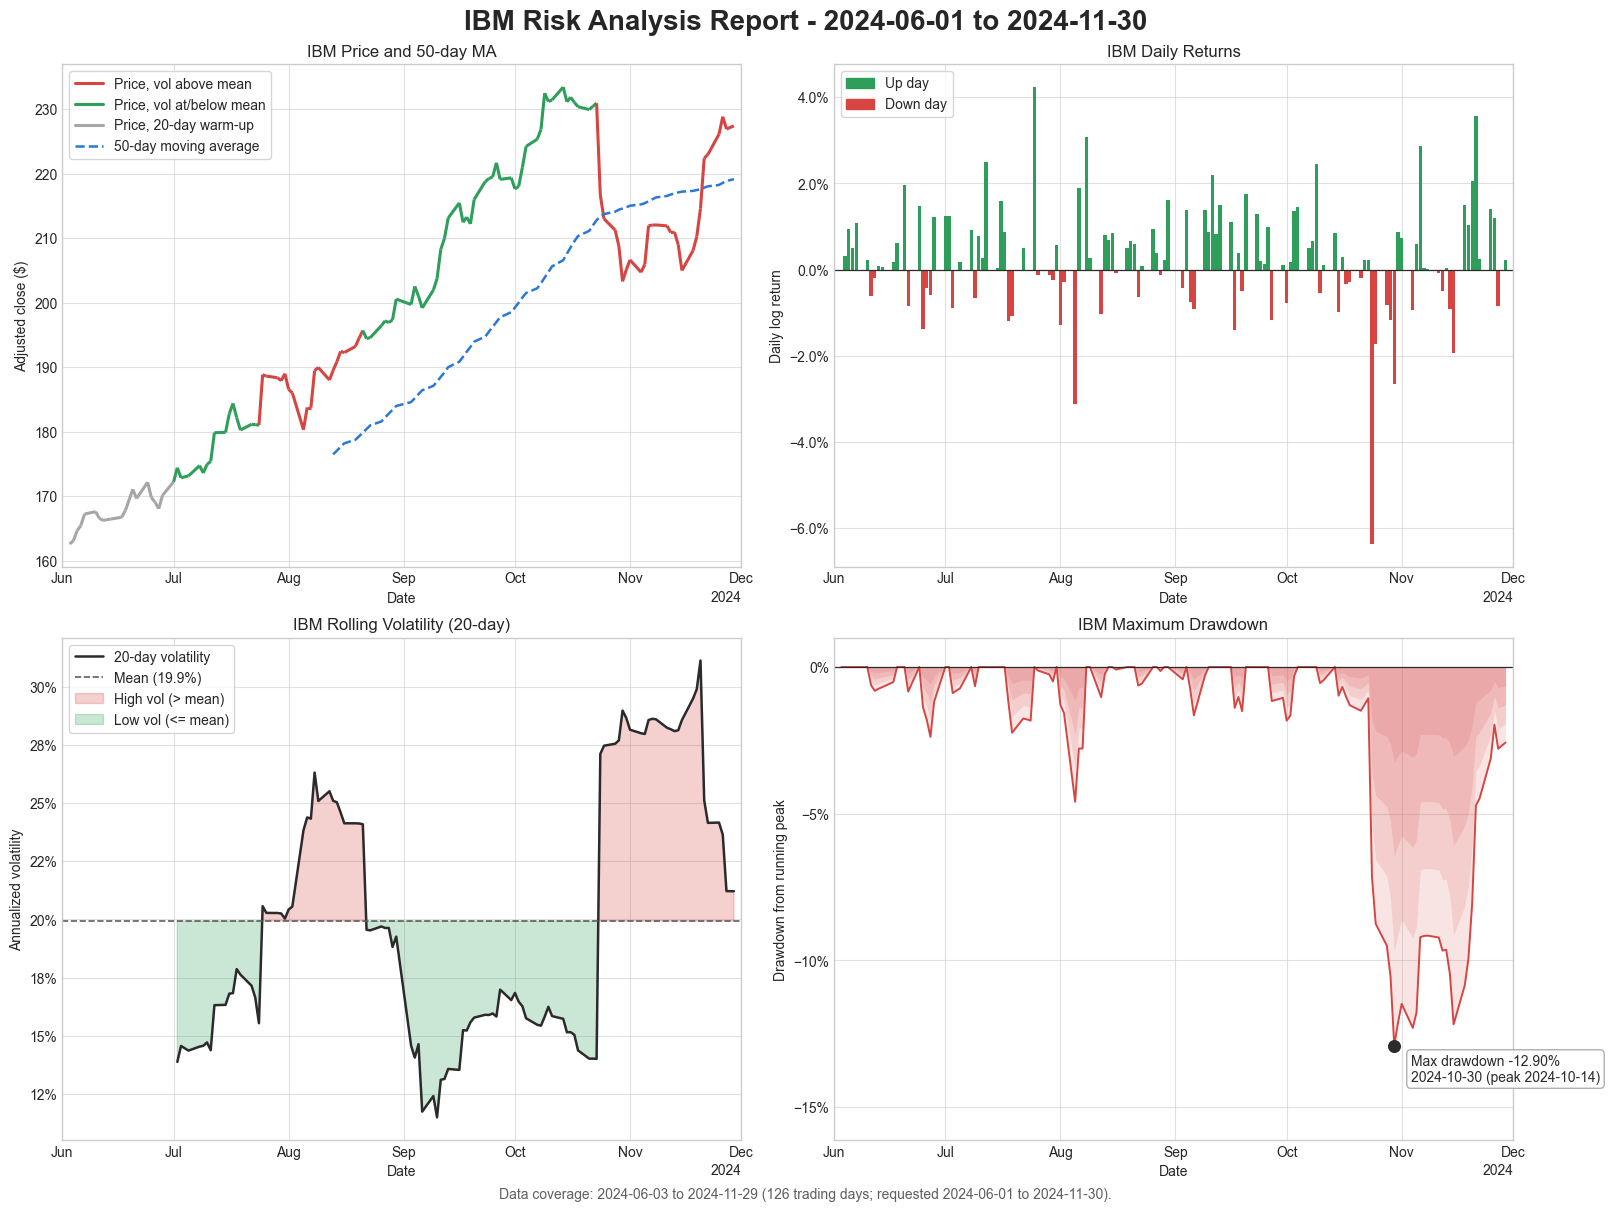

In [10]:
def style_date_axis(ax, index):
    """Apply the shared date range, ticks, x label and grid to one panel so all four line up."""
    pad = pd.Timedelta(days=max(2, (index.max() - index.min()).days // 60))
    ax.set_xlim(index.min() - pad, index.max() + pad)
    locator = mdates.AutoDateLocator(minticks=4, maxticks=9)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_xlabel('Date')
    ax.grid(True, alpha=0.6)


fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=20, fontweight='bold')
fig.supxlabel(coverage, fontsize=10, color=MUTED)

# Top left: price coloured by volatility regime, plus 50-day moving average
ax = axes[0, 0]
ax.plot(df.index, df['adj_close'], alpha=0)                               # sets date units and limits
xy = np.column_stack([mdates.date2num(df.index), df['adj_close'].to_numpy()])
segment_vol = df['volatility'].iloc[1:].to_numpy()                        # colour by each segment's end date
segment_colors = np.where(np.isnan(segment_vol), GRAY, np.where(segment_vol > mean_volatility, RED, GREEN))
ax.add_collection(LineCollection(np.stack([xy[:-1], xy[1:]], axis=1), colors=segment_colors, linewidths=2.2))
legend_items = [Line2D([], [], color=RED, lw=2.2, label='Price, vol above mean'),
                Line2D([], [], color=GREEN, lw=2.2, label='Price, vol at/below mean'),
                Line2D([], [], color=GRAY, lw=2.2, label=f'Price, {volatility_window}-day warm-up')]
if df['sma_50'].notna().any():
    ax.plot(df.index, df['sma_50'], color=ACCENT, lw=1.8, ls='--')
    legend_items.append(Line2D([], [], color=ACCENT, lw=1.8, ls='--', label='50-day moving average'))
else:
    ax.text(0.02, 0.04, f'50-day MA unavailable: needs 50 prices, report has {len(df)}',
            transform=ax.transAxes, fontsize=10, color=MUTED)
ax.legend(handles=legend_items, loc='best', frameon=True, facecolor='white')
ax.set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted close ($)')

# Top right: daily log returns
ax = axes[0, 1]
ax.bar(df.index, df['log_return'] * 100, width=0.9,
       color=np.where(df['log_return'].ge(0), GREEN, RED))
ax.axhline(0, color=INK, lw=0.9)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=1))
ax.legend(handles=[Patch(color=GREEN, label='Up day'), Patch(color=RED, label='Down day')],
          loc='upper left', frameon=True, facecolor='white')
ax.set(title=f'{ticker} Daily Returns', ylabel='Daily log return')

# Bottom left: rolling volatility with regime shading
ax = axes[1, 0]
vol_pct, mean_pct = df['volatility'] * 100, mean_volatility * 100
ax.plot(df.index, vol_pct, color=INK, lw=1.8, label=f'{volatility_window}-day volatility')
ax.axhline(mean_pct, color=MUTED, ls='--', lw=1.2, label=f'Mean ({mean_pct:.1f}%)')
ax.fill_between(df.index, vol_pct, mean_pct, where=vol_pct > mean_pct, interpolate=True,
                color=RED, alpha=0.25, label='High vol (> mean)')
ax.fill_between(df.index, vol_pct, mean_pct, where=vol_pct <= mean_pct, interpolate=True,
                color=GREEN, alpha=0.25, label='Low vol (<= mean)')
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.legend(loc='upper left', frameon=True, facecolor='white')
ax.set(title=f'{ticker} Rolling Volatility ({volatility_window}-day)', ylabel='Annualized volatility')

# Bottom right: drawdown with layered red fills and the maximum marked
ax = axes[1, 1]
dd_pct = df['drawdown'] * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:                                    # deeper = more saturated
    ax.fill_between(df.index, dd_pct * fraction, 0, color=RED, alpha=0.14, lw=0)
ax.plot(df.index, dd_pct, color=RED, lw=1.4)
ax.axhline(0, color=INK, lw=0.9)
ax.scatter([max_drawdown_date], [dd_pct.loc[max_drawdown_date]], s=70, color=INK, zorder=3)
ax.annotate(f'Max drawdown {max_drawdown:.2%}\n{max_drawdown_date:%Y-%m-%d} (peak {peak_date:%Y-%m-%d})',
            (max_drawdown_date, dd_pct.loc[max_drawdown_date]), xytext=(12, -6), textcoords='offset points',
            fontsize=10, color=INK, va='top',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=GRAY, alpha=0.9))
ax.set_ylim(min(dd_pct.min() * 1.25, -1), 1)
ax.yaxis.set_major_locator(MaxNLocator(nbins=8, steps=[1, 2, 5, 10]))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak')

for ax in axes.flat:
    style_date_axis(ax, df.index)
plt.show()

## 4. Summary statistics

Values are stored as **fractions** and formatted only for display. Return-based rows use daily log returns, except **Total Return**, which is `last adj_close / first adj_close - 1`. "Positive Days" divides up days by **all** nonmissing returns, including zero-return days. Any undefined metric displays as `N/A`.

In [11]:
def fmt(value, kind):
    """Display formatting only; the underlying metrics stay numeric fractions."""
    if pd.isna(value):
        return 'N/A'
    return {'signed_pct': f'{value:+.2%}', 'pct': f'{value:.2%}', 'pct1': f'{value:.1%}',
            'ratio': f'{value:.2f}'}[kind]


rows = [('Total Return', 'total_return', 'signed_pct'),
        ('Annualized Return', 'annualized_return', 'signed_pct'),
        ('Annualized Volatility', 'annualized_volatility', 'pct'),
        ('Sharpe Ratio', 'sharpe_ratio', 'ratio'),
        ('Maximum Drawdown', 'max_drawdown', 'signed_pct'),
        ('Best Day', 'best_day', 'signed_pct'),
        ('Worst Day', 'worst_day', 'signed_pct'),
        ('Positive Days', 'positive_days', 'pct1'),
        ('Average Up Day', 'avg_up_day', 'signed_pct'),
        ('Average Down Day', 'avg_down_day', 'signed_pct')]
summary_table = pd.DataFrame({'Metric': [label for label, _, _ in rows],
                              'Value': [fmt(metrics[key], kind) for _, key, kind in rows]})
display(summary_table.set_index('Metric'))

,Value
Metric,
Total Return,+39.88%
Annualized Return,+96.73%
Annualized Volatility,20.42%
Sharpe Ratio,3.22
Maximum Drawdown,-12.90%
Best Day,+4.24%
Worst Day,-6.37%
Positive Days,63.2%
Average Up Day,+0.95%


In [12]:
final_drawdown = df['drawdown'].iloc[-1]
recovery = ('and the price has since recovered to a new high' if np.isclose(final_drawdown, 0)
            else f'and the price ended {fmt(final_drawdown, "signed_pct")} below its running peak')
shorter = (f' **Note:** {ticker} data ends on {last_date:%Y-%m-%d}, before the requested end date, '
           'so these figures cover a shorter period than the requested window.'
           if history_truncated else '')
display(Markdown(
    f"### Key takeaways\n\n"
    f"- **{ticker} returned {fmt(metrics['total_return'], 'signed_pct')}** from {first_date:%Y-%m-%d} to "
    f"{last_date:%Y-%m-%d} ({len(df)} trading days), equivalent to "
    f"{fmt(metrics['annualized_return'], 'signed_pct')} a year compounded.{shorter}\n"
    f"- **Risk:** whole-period annualized volatility was {fmt(metrics['annualized_volatility'], 'pct')} "
    f"(mean {volatility_window}-day rolling volatility {fmt(mean_volatility, 'pct')}), giving a Sharpe ratio "
    f"of **{fmt(metrics['sharpe_ratio'], 'ratio')}** at a {risk_free_rate:.0%} risk-free rate.\n"
    f"- **Drawdown:** the deepest fall from a running peak was **{fmt(max_drawdown, 'signed_pct')}** "
    f"(peak {peak_date:%Y-%m-%d}, trough {max_drawdown_date:%Y-%m-%d}), {recovery}.\n"
    f"- **Day-to-day:** {fmt(metrics['positive_days'], 'pct1')} of days were up. The best day was "
    f"{fmt(metrics['best_day'], 'signed_pct')} and the worst {fmt(metrics['worst_day'], 'signed_pct')} "
    f"(log returns).\n"
    f"- **Data:** {int(df[repair_cols].any(axis=1).sum())} of {len(df)} rows in this window contain a value "
    f"estimated during cleaning; see the provenance table above."
))

### Key takeaways

- **IBM returned +39.88%** from 2024-06-03 to 2024-11-29 (126 trading days), equivalent to +96.73% a year compounded.
- **Risk:** whole-period annualized volatility was 20.42% (mean 20-day rolling volatility 19.93%), giving a Sharpe ratio of **3.22** at a 2% risk-free rate.
- **Drawdown:** the deepest fall from a running peak was **-12.90%** (peak 2024-10-14, trough 2024-10-30), and the price ended -2.57% below its running peak.
- **Day-to-day:** 63.2% of days were up. The best day was +4.24% and the worst -6.37% (log returns).
- **Data:** 8 of 126 rows in this window contain a value estimated during cleaning; see the provenance table above.

## 5. Export results for the batch run (Scrapbook)

`sb.glue` stores named results inside the executed notebook. `03_run_all_stocks.py` reads them back with `sb.read_notebook(path).scraps`, **only** from reports that ran successfully in the current batch, so it never needs to recompute a metric. Metrics are stored as **fractions**, with undefined values as `None`, which JSON can represent.

In [13]:
def as_scrap(value):
    """JSON-safe scalar: numpy -> Python, NaN -> None."""
    value = value.item() if isinstance(value, np.generic) else value
    return None if isinstance(value, float) and not np.isfinite(value) else value


report_summary = {
    'ticker': ticker, 'start_date': f'{start:%Y-%m-%d}', 'end_date': f'{end:%Y-%m-%d}',
    'first_date': f'{first_date:%Y-%m-%d}', 'last_date': f'{last_date:%Y-%m-%d}',
    'trading_days': len(df), 'n_returns': int(returns.count()),
    'covers_requested_end': not history_truncated,
    'data_quality_ok': data_quality_ok,
    'repaired_rows': int(df[repair_cols].any(axis=1).sum()),
    **{key: as_scrap(value) for key, value in metrics.items()},
}
for name, value in report_summary.items():
    sb.glue(name, value)
sb.glue('summary', report_summary)
sb.glue('prices', df.drop(columns=['adj_close_source', 'outlier_class']), encoder='pandas')
sb.glue('analysis_plot', fig, encoder='display', display=False)
print(f'Exported {len(report_summary)} named results plus the price table and figure.')

Exported 22 named results plus the price table and figure.
